# 3. Loops

*Physical Modeling in MATLAB* by Allen B. Downey. Run each code cell in order with Shift+Enter; you can change the code and run it again.

The programs we have seen so far are *straight-line code*; that is, they execute one instruction after another from top to bottom. This chapter introduces one of the most important programming-language features, the `for` loop, which allows simple programs to perform complex, repetitive tasks. This chapter also introduces the mathematical concepts of sequence and series, and a process for writing programs, incremental development.

We’ll start by reviewing the exercise from the previous chapter; if you didn’t do it, you might want to take a look before you go on.

## Updating Variables

In Exercise 2.2, I asked you to write a program that models a bike-share system with bikes moving between two stations. Each day 5 percent of the bikes in Boston are dropped off in Cambridge, and 3 percent of the bikes in Cambridge get dropped off in Boston.

To update the state of the system, you might have been tempted to write something like

*The code in this section uses the variables `b` and `c` from Exercise 2.2. Run this cell first to give them starting values.*

In [2]:
b = 100
c = 100

b = 100


c = 100


In [3]:
b = b - 0.05*b + 0.03*c
c = c + 0.05*b - 0.03*c

b = 98


c = 101.90


But that would be wrong, so very wrong. Why? The problem is that the first line changes the value of `b`, so when the second line runs, it gets the old value of `c` and the new value of `b`. As a result, the change in `b` is not always the same as the change in `c`, which violates the Principle of Conservation of Bikes!

One solution is to use temporary variables like `b_new` and `c_new`:

In [4]:
b_new = b - 0.05*b + 0.03*c
c_new = c + 0.05*b - 0.03*c
b = b_new
c = c_new

b_new = 96.157


c_new = 103.74


b = 96.157


c = 103.74


This has the effect of updating the variables *simultaneously*; that is, it reads both old values before writing either new value.

The following is an alternative solution that has the added advantage of simplifying the computation:

In [5]:
b_to_c = 0.05*b - 0.03*c
b = b - b_to_c
c = c + b_to_c

b_to_c = 1.6956


b = 94.461


c = 105.44


It’s easy to look at this code and confirm that it obeys Conservation of Bikes. Even if the value of `b_to_c` is wrong, at least the total number of bikes is right. And that brings us to the Fifth Theorem of Debugging:

> The best way to avoid a bug is to make it impossible.

In this case, removing redundancy also eliminates the opportunity for a bug.

## Bug Taxonomy

The more you understand bugs, the better you will be at debugging. There are four kinds of bugs:

-   **Syntax error**: You have written a command that cannot execute because it violates one of the language’s syntax rules. For example, in MATLAB, you can’t have two operands in a row without an operator, so `pi r^2` contains a syntax error. When the interpreter finds a syntax error, it prints an error message and stops running your program.

-   **Runtime error**: Your program starts running, but something goes wrong along the way. For example, if you try to access a variable that doesn’t exist, that’s a runtime error. When the interpreter detects the problem, it prints an error message and stops.

-   **Logical error**: Your program runs without generating any error messages, but it doesn’t do the right thing. The problem in the previous section, where we changed the value of `b` before reading the old value, is a logical error.

-   **Numerical error**: Most computations in MATLAB are only approximately right. Most of the time the errors are small enough that we don’t care, but in some cases the round-off errors are a problem.

Syntax errors are usually the easiest to deal with. Sometimes the error messages are confusing, but MATLAB can usually tell you where the error is, at least roughly.

Runtime errors are harder because, as I mentioned before, MATLAB can tell you where it detected the problem, but not what caused it.

Logical errors are hard because MATLAB can’t help at all. From MATLAB’s point of view there’s nothing wrong with the program; only you know what the program is supposed to do, so only you can check it.

Numerical errors can be tricky because it’s not clear whether the problem is your fault. For most simple computations, MATLAB produces the floating-point value that is closest to the exact solution, which means that the first 15 significant digits should be correct.

But some computations are ill-conditioned, which means that even if your program is correct, the round-off errors accumulate and the number of correct digits can be smaller. Sometimes MATLAB can warn you that this is happening, but not always! *Precision* (the number of digits in the answer) does not imply *accuracy* (the number of digits that are right).

## Absolute and Relative Error

There are two ways of thinking about numerical errors. The first is *absolute error*, or the difference between the correct value and the approximation. We often write the magnitude of the error, ignoring its sign, when it doesn’t matter whether the approximation is too high or too low.

The second way to think about numerical errors is *relative error*, where the error is expressed as a fraction (or percentage) of the exact value.

For example, we might want to estimate $9!$ using the formula $\sqrt {18 \pi} ( 9 / e)^9$. The exact answer is $9 \cdot 8 \cdot 7 \cdot 6
\cdot 5 \cdot 4 \cdot 3 \cdot 2 \cdot 1 = 362,880$. The approximation is $359,536.87$. So the absolute error is $3,343.13$.

At first glance, that sounds like a lot—we’re off by three thousand—but we should consider the size of the thing we are estimating. For example, \$3,000 matters a lot if we’re talking about an annual salary, but not at all if we’re talking about the national debt.

A natural way to handle this problem is to use relative error. In this case, we would divide the error by $362,880$, yielding $0.00921$, which is just less than 1 percent. For many purposes, being off by 1 percent is good enough.

## for Loops

Let’s return to the bike-share example. In the previous chapter, we wrote a *bike_update.m* script to simulate a day in the life of a bike-share system. To simulate an entire month, we’d have to run the script 30 times. We could enter the same command 30 times, but it’s simpler to use a *loop*, which is a set of statements that executes repeatedly.

To create a loop, we can use the `for` statement, like this:

In [6]:
for i=1:30
    bike_update
end

b = 92.461
c = 107.44
b = 90.461
c = 109.44
b = 88.461
c = 111.44
b = 87.461
c = 112.44
b = 86.461
c = 113.44
b = 85.461
c = 114.44
b = 84.461
c = 115.44
b = 83.461
c = 116.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44
b = 82.461
c = 117.44


The first line includes what looks like an assignment statement, and it *is* like an assignment statement, except that it runs more than once. The first time, it creates the variable `i` and assigns it the value 1. The second time, `i` gets the value 2, and so on, up to and including 30.

The colon operator (`:`) specifies a *range* of integers. You can create a range at the prompt:

In [7]:
1:5

ans =

   1   2   3   4   5



The variable you use in the `for` statement is called the *loop variable*. It’s common to use the names `i`, `j`, and `k` as loop variables.

The statements inside the loop are called the *body*. By convention, they are indented to show that they’re inside the loop, but the indentation doesn’t affect the execution of the program. The `end` statement marks the end of the loop.

To see a loop in action you can run one that displays the loop variable:

In [8]:
for i=1:5
    i
end

i = 1
i = 2
i = 3
i = 4
i = 5


As this example shows, you *can* run a `for` loop from the command line, but it’s more common to put it in a script.

**Exercise 3.1.** Create a script named *bike_loop.m* that uses a `for` loop to run *bike_update.m* 30 times. Before you run it, you have to assign values to `b` and `c`. For this exercise, start with the values **`b = 100`** and **`c = 100`**.

If everything goes smoothly, your script will display a long stream of numbers on the screen. It’s probably too long to fit, and even if it did fit, it would be hard to interpret. A graph would be much better!

## Plotting

If the output of your program is a long stream of numbers, it can be hard to see what is happening. Plotting the results can make things clearer.

The `plot` function is a versatile tool for plotting two-dimensional graphs. Unfortunately, it’s so versatile that it can be hard to use (and hard to read the documentation). We’ll start simple and work our way up.

To plot a single point, type

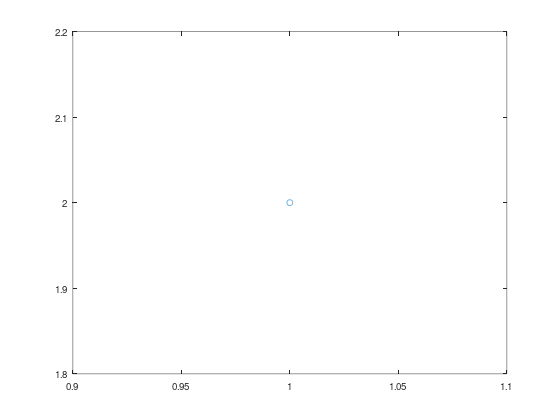

In [9]:
plot(1, 2, 'o')

A Figure Window should appear with a graph and a single blue circle at $x$ position 1 and $y$ position 2.

The letter in single quotes is a *style string* that specifies how the point should be plotted; `o` indicates a circle. Other shapes include `+`, `*`, `x`, `s` (for a square), `d` (for a diamond), and `^` (for a triangle).

You can also specify the color by starting the style string with a color code:

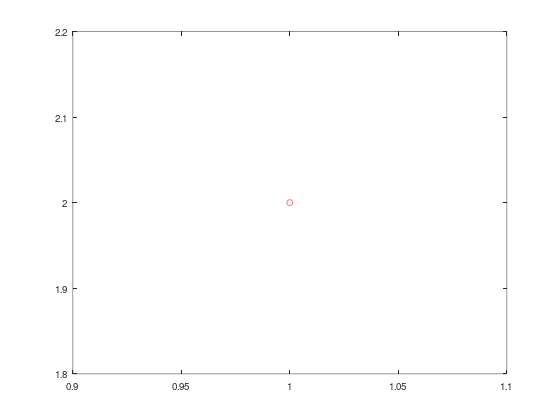

In [10]:
plot(1, 2, 'ro')

Here, `r` stands for red; the other colors include `g` for green, `b` for blue, `c` for cyan, `m` for magenta, `y` for yellow, and `k` for black.

When you use `plot` this way, it can only plot one point at a time. If you run `plot` again, it clears the figure before making the new plot. The `hold` command lets you override that behavior: `hold on` tells MATLAB not to clear the figure when it makes a new plot; `hold off` returns to the default behavior.

Try this:

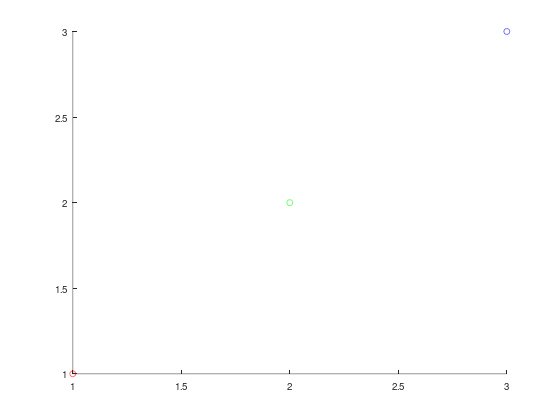

In [11]:
clf
hold on
plot(1, 1, 'ro')
plot(2, 2, 'go')
plot(3, 3, 'bo')
hold off

The `clf` command clears the figure before we start plotting.

If you run the code above, you should see a figure with three circles. MATLAB scales the plot automatically so that the axes run from the lowest values in the plot to the highest.

**Exercise 3.2.** Modify *bike_loop.m* so that it clears the figure before running the loop. Then, each time through the loop, it should plot the value of `b` versus the value of `i` with a red circle.

Once you get that working, modify it so it plots the values of `c` with blue diamonds.

## Sequences

Now that we have the ability to write loops, we can use them to explore sequences and series, which are useful for describing and analyzing systems that change over time.

In mathematics, a *sequence* is a set of numbers that corresponds to the positive integers. The numbers in the sequence are called *elements*. In math notation, the elements are denoted with subscripts, so the first element of the series $A$ is $A_1$, followed by $A_2$, and so on.

A `for` loop is a natural way to compute the elements of a sequence. As an example, in a geometric sequence, each element is a constant multiple of the previous element. As a more specific example, let’s look at the sequence with $A_1 = 1$ and the relationship $A_{i+1} = A_i/2$, for all $i$. In other words, each element is half as big as the one before it.

The following loop computes the first 10 elements of $A$:

In [12]:
a = 1
for i=2:10
    a = a/2
end

a = 1


a = 0.5000
a = 0.2500
a = 0.1250
a = 0.062500
a = 0.031250
a = 0.015625
a = 7.8125e-03
a = 3.9062e-03
a = 1.9531e-03


The first line initializes the variable `a` with the first element of the sequence, $A_1$. Each time through the loop, we find the next value of `a` by dividing the previous value by 2, and assign the result back to `a`. At the end, `a` contains the 10th element.

The other elements are displayed on the screen, but they are not saved in a variable. Later, we’ll see how to save the elements of a sequence in a vector.

This loop computes the sequence *recurrently*, which means that each element depends on the previous one. For this sequence, it’s also possible to compute the $i$th element *directly*, as a function of $i$, without using the previous element.

In math notation, $A_i = A_1 r^{i-1}$, where $r$ is the ratio of successive elements. In the previous example, $A_{i+1} = A_i/2$, so $r = 1/2$.

**Exercise 3.3.** Write a script named *sequence.m* that uses a loop to compute elements of $A$ directly.

## Series

In mathematics, a *series* is the sum of the elements of a sequence. It’s a terrible name, because in common English, “sequence” and “series” mean pretty much the same thing, but in math, a sequence is a set of numbers, and a series is an expression (a sum) that has a single value. In math notation, a series is often written using the summation symbol $\sum$.

For example, the sum of the first 10 elements of $A$ is $$\sum_{i=1}^{10} A_i$$

A `for` loop is a natural way to compute the value of this series:

*Listing 3.1: A program that calculates a simple series*

In [13]:
A1 = 1;
total = 0;
for i=1:10
    a = A1 * (1/2)^(i-1);
    total = total + a;
end
ans = total

ans = 1.9980


Let’s walk through what’s happening here. `A1` is the first element of the sequence, so we assign it to be `1`; we also create `total`, which will store the cumulative sum. Each time through the loop, we set `a` to the $i$th element and add `a` to the `total`. At the end, outside the loop, we store `total` as `ans`.

The way we’re using `total` is called an *accumulator*, that is, a variable that accumulates the result a little bit at a time.

**Exercise 3.4.** This example computes the terms of the series directly. As an exercise, write a script named *series.m* that computes the same sum by computing the elements recurrently. You will have to be careful about where you start and stop the loop.

## Generalization

As written, the previous example always adds up the first 10 elements of the sequence, but we might be curious to know what happens to `total` as we increase the number of terms in the series. If you’ve studied geometric series, you might know that this series converges on 2; that is, as the number of terms goes to infinity, the sum approaches 2 asymptotically.

To see if that’s true for our program, we can replace the constant `10` in Listing 3.1 with a variable named `n`:

*Listing 3.2: Updating our code from Listing 3.1 to have a variable number of terms*

```
A1 = 1;
total = 0;
for i=1:n
    a = A1 * (1/2)^(i-1);
    total = total + a;
end
ans = total
```

The code in Listing 3.2 can now compute any number of terms, with the precondition that you have to set `n` before you execute the code. I put this code in a file named *series.m*, then ran it with different values of `n`:

In [14]:
n=10; series
n=20; series
n=30; series
n=40; series

ans = 1.9980


ans = 2.0000


ans = 2.0000


ans = 2.0000


It sure looks like it’s converging on 2.

Replacing a constant with a variable is called *generalization*. Instead of computing a fixed, specific number of terms, the new script is more general; it can compute any number of terms. This is an important idea we’ll come back to when we talk about functions.

## Incremental Development

As you start writing longer programs, you might find yourself spending more time debugging. The more code you write before you start debugging, the harder it is to find the problem.

*Incremental development* is a way of programming that tries to minimize the pain of debugging by developing and testing in small steps. The fundamental steps are:

1.  Always start with a working program. If you have an example from a book, or a program you wrote that is similar to what you are working on, start with that. Otherwise, start with something you *know* is correct, like `x = 5`. Run the program and confirm that you are running the program you think you are running. This step is important, because in most environments there are little things that can trip you up when you start a new project. Get them out of the way so you can focus on programming.

2.  Make one small, testable change at a time. A *testable* change is one that displays something on the screen (or has some other effect) that you can check. Ideally, you should know what the correct answer is or be able to check it by performing another computation.

3.  Run the program and see if the change worked. If so, go back to step 2. If not, you’ll have to do some debugging, but if the change you made was small, it shouldn’t take long to find the problem.

With incremental development, your code is more likely to work the first time, and if it doesn’t, the problem is more likely to be obvious. And that brings us to the Sixth Theorem of Debugging:

> The best kind of debugging is the kind you don’t have to do.

In practice, there are two problems with incremental development. First, sometimes you have to write extra code to generate visible output that you can check. This extra code is called *scaffolding* because you use it to build the program and then remove it when you are done. But the time you save on debugging is almost always worth the time you invest in scaffolding.

The second problem is that when you’re getting started, you might not know how to choose steps that get from `x = 5` to the program you’re trying to write. We’ll look at an extended example in Chapter 6.

If you find yourself writing more than a few lines of code before you start testing and you’re spending a lot of time debugging, you should try incremental development.

## Chapter Review

In this chapter, we used a loop to perform a repetitive computation—updating a model 30 times—and to compute sequences and series. Also, we used the `plot` function to visualize the results.

Here are some terms from this chapter you might want to remember.

*Absolute error* is the difference between an approximation and an exact answer. *Relative error* is the same difference expressed as a fraction or percentage of the exact answer.

A *loop* is part of a program that runs repeatedly. A *loop variable* is a variable that gets assigned a different value each time through the loop. A *range* is a sequence of values assigned to the loop variable, often specified with the colon operator—for example, `1:5`. The *body* of a loop is the set of statements inside the loop that runs repeatedly. An *accumulator* is a variable that is used to accumulate a result a little bit at a time.

In mathematics, a *sequence* is a set of numbers that correspond to the positive integers. The numbers that make up the sequence are called *elements*. A *series* is the sum of a sequence of elements. Sometimes we compute the elements of a sequence *recurrently*, which means that each new element depends on previous elements. Sometimes we can compute the elements *directly*, without using previous elements.

*Generalization* is a way to make a program more versatile, for example, by replacing a specific value with a variable that can have any value. *Incremental development* is a way of programming by making a series of small, testable changes. *Scaffolding* is code you write to help you program or debug but that is not part of the finished program.

In the next chapter, we’ll use a vector to store the results from a loop.

## Exercises

Before you go on, you might want to work on the following exercises.

**Exercise 3.5.** Years ago I was in a fudge shop and saw a sign that said “Buy one pound of fudge, get another quarter pound free.” That’s simple enough.

But if I ran the fudge shop, I would offer a special deal to anyone who could solve the following problem:

> If you buy a pound of fudge, we’ll give you another quarter pound free. And then we’ll give you a quarter of a quarter pound, or one-sixteenth. And then we’ll give you a quarter of that, and so on. How much fudge would you get in total?

Write a script called *fudge.m* that solves this problem. Hint: start with *series.m* and generalize it by replacing the ratio `1/2` with a variable, `r`.

**Exercise 3.6.** We have already seen the Fibonacci sequence, $F$, which is defined recurrently as

$$\mathrm{for}~i \ge 3, \quad  F_{i} = F_{i-1} + F_{i-2}$$

In order to get started, you have to specify the first two elements, but once you have those, you can compute the rest. The most common Fibonacci sequence starts with $F_1 = 1$ and $F_2 = 1$.

Write a script called *fibonacci2.m* that uses a `for` loop to compute the first 10 elements of this Fibonacci sequence. As a postcondition, your script should assign the 10th element to `ans`.

Now generalize your script so that it computes the $n$th element for any value of `n`, with the precondition that you have to set `n` before you run the script. To keep things simple for now, you can assume that `n` is greater than 0.

Hint: you’ll have to use two variables to keep track of the previous two elements of the sequence. You might want to call them `prev1` and `prev2`. Initially, `prev1` = $F_1$ and `prev2` = $F_2$. At the end of the loop, you’ll have to update `prev1` and `prev2`; think carefully about the order of the updates!

In [15]:
% Solution

% Simulates the bike share system for one month

b = 100
c = 100

for i=1:30
    bike_update
end

b = 100


c = 100


b = 98
c = 102
b = 96
c = 104
b = 94
c = 106
b = 92
c = 108
b = 90
c = 110
b = 88
c = 112
b = 87
c = 113
b = 86
c = 114
b = 85
c = 115
b = 84
c = 116
b = 83
c = 117
b = 83
c = 117
b = 83
c = 117
b = 83
c = 117
b = 83
c = 117
b = 83
c = 117
b = 83
c = 117
b = 83
c = 117
b = 83
c = 117
b = 83
c = 117
b = 83
c = 117
b = 83
c = 117
b = 83
c = 117
b = 83
c = 117
b = 83
c = 117
b = 83
c = 117
b = 83
c = 117
b = 83
c = 117
b = 83
c = 117
b = 83
c = 117


b = 100


c = 100


b = 98


c = 102


b = 96


c = 104

... (47 outputs left out)


c = 117


b = 83


c = 117


b = 83
c = 117
b = 83
c = 117
b = 83
c = 117


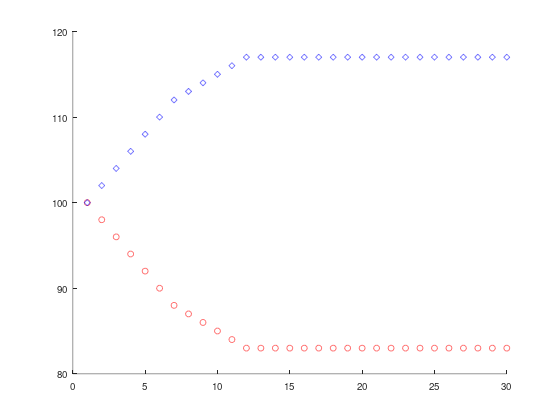

In [16]:
% Solution

% Simulates the bike share system for one month

b = 100
c = 100

clf
hold on
for i=1:30
    plot(i, b, 'ro')
    plot(i, c, 'bd')
    bike_update
end
hold off

In [17]:
% Solution

% Compute the first 10 elements of a geometric sequence

for i=1:10
    a = 1*(1/2)^(i-1)
end

a = 1
a = 0.5000
a = 0.2500
a = 0.1250
a = 0.062500
a = 0.031250
a = 0.015625
a = 7.8125e-03
a = 3.9062e-03
a = 1.9531e-03


In [18]:
% Solution

% Compute the sum of `n` elements of a geometric sequence, recurrently
% (exercise solution; series.m computes the elements directly)

a = 1;
total = a;

for i=2:n
    a = a/2;
    total = total + a;
end
ans = total

ans = 2.0000


In [19]:
% Solution

% Compute the sum of `n` elements of a geometric sequence

a = 1;
total = a;
r = 1/4;

for i=2:n
    a = a * r;
    total = total + a;
end
ans = total

ans = 1.3333


In [20]:
% Solution

% Computes the nth Fibonacci number.
% Precondition: `n` must be a positive integer.
% Postcondition: the result is stored in `ans`.

prev1 = 1;
prev2 = 1;
f = 1;

for i=3:n
    f = prev1 + prev2;
    prev2 = prev1;
    prev1 = f;
end
ans = f

ans = 1.0233e+08
